In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score


In [ ]:
# Basic setup
IMG_SIZE = 128     # Smaller size => Faster training
BATCH_SIZE = 32
EPOCHS = 15
NUM_CLASSES = 5


# Data augmentation & split
datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

train_gen = datagen.flow_from_directory(
    dataset_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

val_gen = datagen.flow_from_directory(
    dataset_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

Found 4040 images belonging to 5 classes.
Found 1008 images belonging to 5 classes.


In [ ]:
# Load MobileNetV2 base
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = False  # Freeze pretrained layers

# Add custom layers
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.4)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
output = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

# Compile
model.compile(optimizer=Adam(learning_rate=0.0005),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Train model
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=[early_stop],
    verbose=1
)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
127/127 ━━━━━━━━━━━━━━━━━━━━ 1846s 14s/step - accuracy: 0.6108 - loss: 1.1698 - val_accuracy: 0.7629 - val_loss: 0.6519
Epoch 2/15
127/127 ━━━━━━━━━━━━━━━━━━━━ 20s 159ms/step - accuracy: 0.8323 - loss: 0.4869 - val_accuracy: 0.7976 - val_loss: 0.5344
Epoch 3/15
127/127 ━━━━━━━━━━━━━━━━━━━━ 20s 154ms/step - accuracy: 0.8687 - loss: 0.3676 - val_accuracy: 0.8284 - val_loss: 0.4845
Epoch 4/15
127/127 ━━━━━━━━━━━━━━━━━━━━ 20s 159ms/step - accuracy: 0.8942 - loss: 0.3041 - val_accuracy: 0.8304 - val_loss: 0.4716
Epoch 5/15
127/127 ━━━━━━━━━━━━━━━━━━━━ 20s 154ms/step - accuracy: 0.9138 - loss: 0.2639 - val_accuracy: 0.8651 - val_loss: 0.4157
Epoch 6/15
127/127 ━━━━━━━━━━━━━━━━━━━━ 20s 159ms/step - accuracy: 0.9016 - loss: 0.2644 - val_accuracy: 0.8512 - val_loss: 0.3904
Epoch 7/15
127/127 ━━━━━━━━━━━━━━━━━━━━ 19s 152ms/step - accuracy: 0.9218 - loss: 0.2332 - val_accuracy: 0.8522 - val_loss: 0.4434
Epoch 8/15
127/127 ━━━━━━━━━━━━━━━━━━━━ 21s 156ms/step - accuracy: 0.9389 - loss: 0

In [ ]:
def plot_metrics(history):
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Acc')
    plt.plot(history.history['val_accuracy'], label='Val Acc')
    plt.title('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title('Loss')
    plt.legend()
    plt.show()

plot_metrics(history)


In [ ]:
# Feature extraction for Random Forest
feature_extractor = Model(inputs=base_model.input, outputs=GlobalAveragePooling2D()(base_model.output))

# Extract features from training data
X_train, y_train = [], []
for images, labels in train_gen:
    features = feature_extractor.predict(images)
    X_train.append(features)
    y_train.append(labels)
    if len(X_train) * BATCH_SIZE >= train_gen.samples:
        break

X_train = np.concatenate(X_train)
y_train = np.argmax(np.concatenate(y_train), axis=1)

# Extract features from validation data
X_val, y_val = [], []
for images, labels in val_gen:
    features = feature_extractor.predict(images)
    X_val.append(features)
    y_val.append(labels)
    if len(X_val) * BATCH_SIZE >= val_gen.samples:
        break

X_val = np.concatenate(X_val)
y_val = np.argmax(np.concatenate(y_val), axis=1)

# Train Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Predict and evaluate
y_pred = rf.predict(X_val)
print("\n✅ Random Forest Accuracy:", accuracy_score(y_val, y_pred))
print("\n📋 Classification Report:\n", classification_report(y_val, y_pred, target_names=list(train_gen.class_indices.keys())))


In [ ]:
model.save('/content/drive/MyDrive/teeth_model.h5')


In [ ]:
import os
import numpy as np
from tensorflow.keras.preprocessing import image
from google.colab import drive

# Mount Google Drive
drive.mount('/content/Mydrive')

# Define the image size used for the model
IMG_SIZE = 224  # Change this based on your model input size

# Set image path (make sure the file exists at this location)
img_path = "/content/drive/MyDrive/teeth_dataset/caries/sample.jpg"

# Check if file exists
if not os.path.exists(img_path):
    print("Image not found at path:", img_path)
else:
    # Load and preprocess image
    img = image.load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Predict
    prediction = model.predict(img_array)
    predicted_class = np.argmax(prediction)

    # Map class index to label
    class_names = list(train_generator.class_indices.keys())
    print("Predicted:", class_names[predicted_class])


In [ ]:
!unzip -q /content/Tooth_dataset.zip -d /content/ToothData
!ls /content/ToothData

unzip:  cannot find or open /content/Tooth_dataset.zip, /content/Tooth_dataset.zip.zip or /content/Tooth_dataset.zip.ZIP.
Tooth_dataset


In [ ]:
!ls /content

sample_data  ToothData	Tooth_dataset-20261027T052658Z-1-001.zip


In [ ]:
!unzip -q /content/Tooth_dataset-20261027T052658Z-1-001.zip -d /content/ToothData
!ls /content/ToothData

replace /content/ToothData/Tooth_dataset/Calculus/(1072).jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
Tooth_dataset


In [ ]:
!ls /content/*.zip

/content/Tooth_dataset-20261027T052658Z-1-001.zip


In [ ]:
!ls /content/ToothData/Tooth_dataset

 Calculus   caries   hypodontia  'Mouth Ulcer'	'Tooth Discoloration'


In [ ]:
dataset_path = '/content/ToothData/Tooth_dataset'

In [ ]:
!ls /content/ToothData/Tooth_dataset

 Calculus   caries   hypodontia  'Mouth Ulcer'	'Tooth Discoloration'


In [ ]:
!for d in /content/ToothData/Tooth_dataset/*; do echo "$d: $(ls "$d" | wc -l)"; done

/content/ToothData/Tooth_dataset/Calculus: 1296
/content/ToothData/Tooth_dataset/caries: 219
/content/ToothData/Tooth_dataset/hypodontia: 1251
/content/ToothData/Tooth_dataset/Mouth Ulcer: 265
/content/ToothData/Tooth_dataset/Tooth Discoloration: 2017


In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

weights = compute_class_weight('balanced', classes=np.unique(train_gen.classes), y=train_gen.classes)
class_weight = dict(enumerate(weights))

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=[early_stop],
    class_weight=class_weight
)

NameError: name 'model' is not defined

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Class weights for the imbalanced classes
weights = compute_class_weight('balanced', classes=np.unique(train_gen.classes), y=train_gen.classes)
class_weight = dict(enumerate(weights))
print(class_weight)

# Build model
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.4)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
output = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

model.compile(optimizer=Adam(learning_rate=0.0005),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Train
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=[early_stop],
    class_weight=class_weight
)

{0: np.float64(0.7791706846673095), 1: np.float64(3.811320754716981), 2: np.float64(0.5006195786864932), 3: np.float64(4.590909090909091), 4: np.float64(0.8071928071928072)}
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
127/127 ━━━━━━━━━━━━━━━━━━━━ 34s 171ms/step - accuracy: 0.6032 - loss: 1.1902 - val_accuracy: 0.6786 - val_loss: 0.8744
Epoch 2/15
127/127 ━━━━━━━━━━━━━━━━━━━━ 9s 68ms/step - accuracy: 0.7696 - loss: 0.6908 - val_accuracy: 0.6647 - val_loss: 0.9342
Epoch 3/15
127/127 ━━━━━━━━━━━━━━━━━━━━ 9s 72ms/step - accuracy: 0.8119 - loss: 0.5441 - val_accuracy: 0.7560 - val_loss: 0.6639
Epoch 4/15
127/127 ━━━━━━━━━━━━━━━━━━━━ 9s 67ms/step - accuracy: 0.8498 - loss: 0.4583 - val_accuracy: 0.7411 - val_loss: 0.7061
Epoch 5/15
127/127 ━━━━━━━━━━━━━━━━━━━━ 9s 70ms/step - accuracy: 0.8592 - loss: 0.4180 - val_accuracy: 0.7659 - val_loss: 0.6259
Epoch 6/15
127/127 ━━━━━━━━━━━━━━━━━━━━ 9s 69ms/step - accuracy: 0.8671 - loss: 0.3792 - val_accuracy: 0.7976 - val_loss: 0.5572
E

In [ ]:
# Cell 1: Shared setup
import numpy as np, pandas as pd, tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.applications import MobileNetV3Large, DenseNet121, EfficientNetB0
from tensorflow.keras.applications.densenet import preprocess_input as densenet_pre
from sklearn.metrics import classification_report, accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight

IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 15
NUM_CLASSES = 5
dataset_path = '/content/ToothData/Tooth_dataset'

def make_generators(preprocess_fn=None):
    datagen = ImageDataGenerator(preprocessing_function=preprocess_fn, validation_split=0.2)
    train = datagen.flow_from_directory(dataset_path, target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE, class_mode='categorical', subset='training', shuffle=True)
    val = datagen.flow_from_directory(dataset_path, target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE, class_mode='categorical', subset='validation', shuffle=False)
    return train, val

# Same class weights for every model (handles the imbalance)
_tmp_train, _ = make_generators()
weights = compute_class_weight('balanced', classes=np.unique(_tmp_train.classes), y=_tmp_train.classes)
class_weight = dict(enumerate(weights))
class_names = list(_tmp_train.class_indices.keys())
print(class_weight)

Found 4040 images belonging to 5 classes.
Found 1008 images belonging to 5 classes.
{0: np.float64(0.7791706846673095), 1: np.float64(3.811320754716981), 2: np.float64(0.5006195786864932), 3: np.float64(4.590909090909091), 4: np.float64(0.8071928071928072)}


In [ ]:
# Cell 2: Model builders and training function
def build_model(base_cls):
    base = base_cls(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    x = GlobalAveragePooling2D()(base.output)
    x = Dropout(0.4)(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.3)(x)
    out = Dense(NUM_CLASSES, activation='softmax')(x)
    model = Model(base.input, out)
    model.compile(optimizer=Adam(learning_rate=0.0005),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# name: (base class, preprocessing function)
configs = {
    'MobileNetV3Large': (MobileNetV3Large, None),       # preprocessing is built in
    'DenseNet121':      (DenseNet121, densenet_pre),    # needs its own preprocessing
    'EfficientNetB0':   (EfficientNetB0, None),         # preprocessing is built in
}

def train_and_eval(name, base_cls, pre_fn):
    print(f"\n===== {name} =====")
    train_gen, val_gen = make_generators(pre_fn)
    model = build_model(base_cls)
    early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
    history = model.fit(train_gen, validation_data=val_gen, epochs=EPOCHS,
                        callbacks=[early_stop], class_weight=class_weight, verbose=1)
    val_gen.reset()
    y_pred = np.argmax(model.predict(val_gen), axis=1)
    y_true = val_gen.classes
    print(classification_report(y_true, y_pred, target_names=class_names))
    model.save(f'/content/{name}.keras')
    return history, {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Macro F1': f1_score(y_true, y_pred, average='macro'),
        'Weighted F1': f1_score(y_true, y_pred, average='weighted'),
    }

In [ ]:
# Cell 3: Train all three
histories, results = {}, []
for name, (base_cls, pre_fn) in configs.items():
    histories[name], row = train_and_eval(name, base_cls, pre_fn)
    results.append(row)
    tf.keras.backend.clear_session()   # frees memory between models


===== MobileNetV3Large =====
Found 4040 images belonging to 5 classes.
Found 1008 images belonging to 5 classes.


/usr/local/lib/python3.13/dist-packages/keras/src/applications/mobilenet_v3.py:519: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
127/127 ━━━━━━━━━━━━━━━━━━━━ 46s 209ms/step - accuracy: 0.6099 - loss: 1.1673 - val_accuracy: 0.6647 - val_loss: 0.8463
Epoch 2/15
127/127 ━━━━━━━━━━━━━━━━━━━━ 9s 68ms/step - accuracy: 0.7866 - loss: 0.6711 - val_accuracy: 0.6964 - val_loss: 0.7544
Epoch 3/15
127/127 ━━━━━━━━━━━━━━━━━━━━ 8s 65ms/step - accuracy: 0.8252 - loss: 0.5634 - val_accuracy: 0.7222 - val_loss: 0.7241
Epoch 4/15
127/127 ━━━━━━━━━━━━━━━━━━━━ 8s 66ms/step - accuracy: 0.8572 - loss: 0.4578 - val_accuracy: 0.6944 - val_loss: 0.7879
Epoch 5/15
127/127 ━━━━━━━━━━━━━━━━━━━━ 8s 65ms/step - accuracy: 0.8673 - loss: 0.4230 - val_accuracy: 0.7014 - val_loss: 0.8308
Epoch 6/15
127/127 ━━━━━━━━━━━━━━━━━━━━ 8s 66ms/step - accuracy: 0.8844 - loss: 0.3446 - val_accuracy: 0.7480 - val_loss: 0.7207
Epoch 7/15
127/127 ━━━━━━━━━━━━━━━━━━━━ 8s 66ms/step - accuracy: 0.8975 - loss: 0.3149 - val_accuracy: 0.7341 - val_loss: 0.7717
Epoch 8/15
127/127 ━━━━━━━━━━━━━━━━━━━━ 10s 

           Model  Accuracy  Macro F1  Weighted F1
MobileNetV3Large    0.7808    0.7291       0.7861
     DenseNet121    0.6835    0.6525       0.6963
  EfficientNetB0    0.8175    0.7647       0.8229


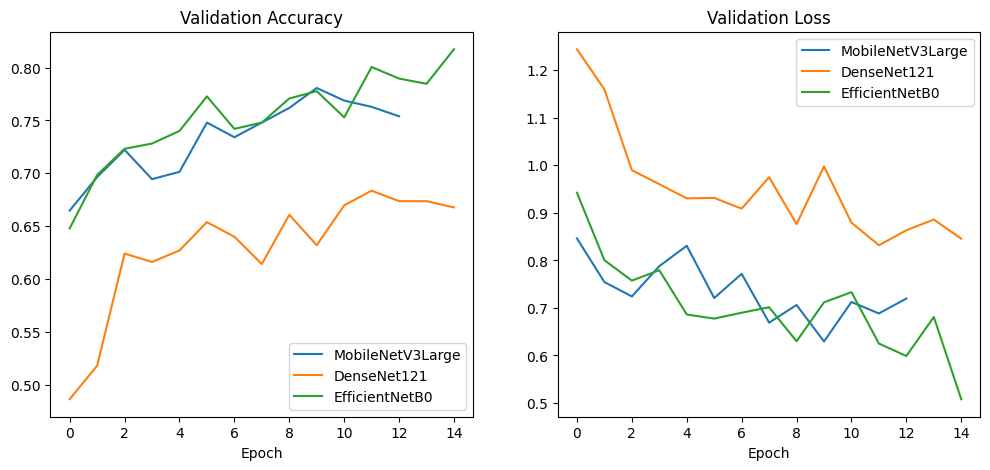

In [ ]:
# Cell 4: Comparison table and curves
import matplotlib.pyplot as plt

print(pd.DataFrame(results).round(4).to_string(index=False))

plt.figure(figsize=(12, 5))
for i, (metric, title) in enumerate([('val_accuracy', 'Validation Accuracy'), ('val_loss', 'Validation Loss')]):
    plt.subplot(1, 2, i + 1)
    for name, h in histories.items():
        plt.plot(h.history[metric], label=name)
    plt.title(title); plt.xlabel('Epoch'); plt.legend()
plt.show()

In [ ]:
# Cell 5: Reload the saved models and collect predictions
from tensorflow.keras.models import load_model

preds = {}
for name, (base_cls, pre_fn) in configs.items():
    _, val_gen = make_generators(pre_fn)
    model = load_model(f'/content/{name}.keras')
    val_gen.reset()
    probs = model.predict(val_gen, verbose=0)
    preds[name] = {
        'y_true': val_gen.classes,
        'probs': probs,
        'y_pred': np.argmax(probs, axis=1),
        'params': model.count_params(),
    }
    tf.keras.backend.clear_session()
print("Done:", list(preds.keys()))

Found 4040 images belonging to 5 classes.
Found 1008 images belonging to 5 classes.
Found 4040 images belonging to 5 classes.
Found 1008 images belonging to 5 classes.
Found 4040 images belonging to 5 classes.
Found 1008 images belonging to 5 classes.
Done: ['MobileNetV3Large', 'DenseNet121', 'EfficientNetB0']


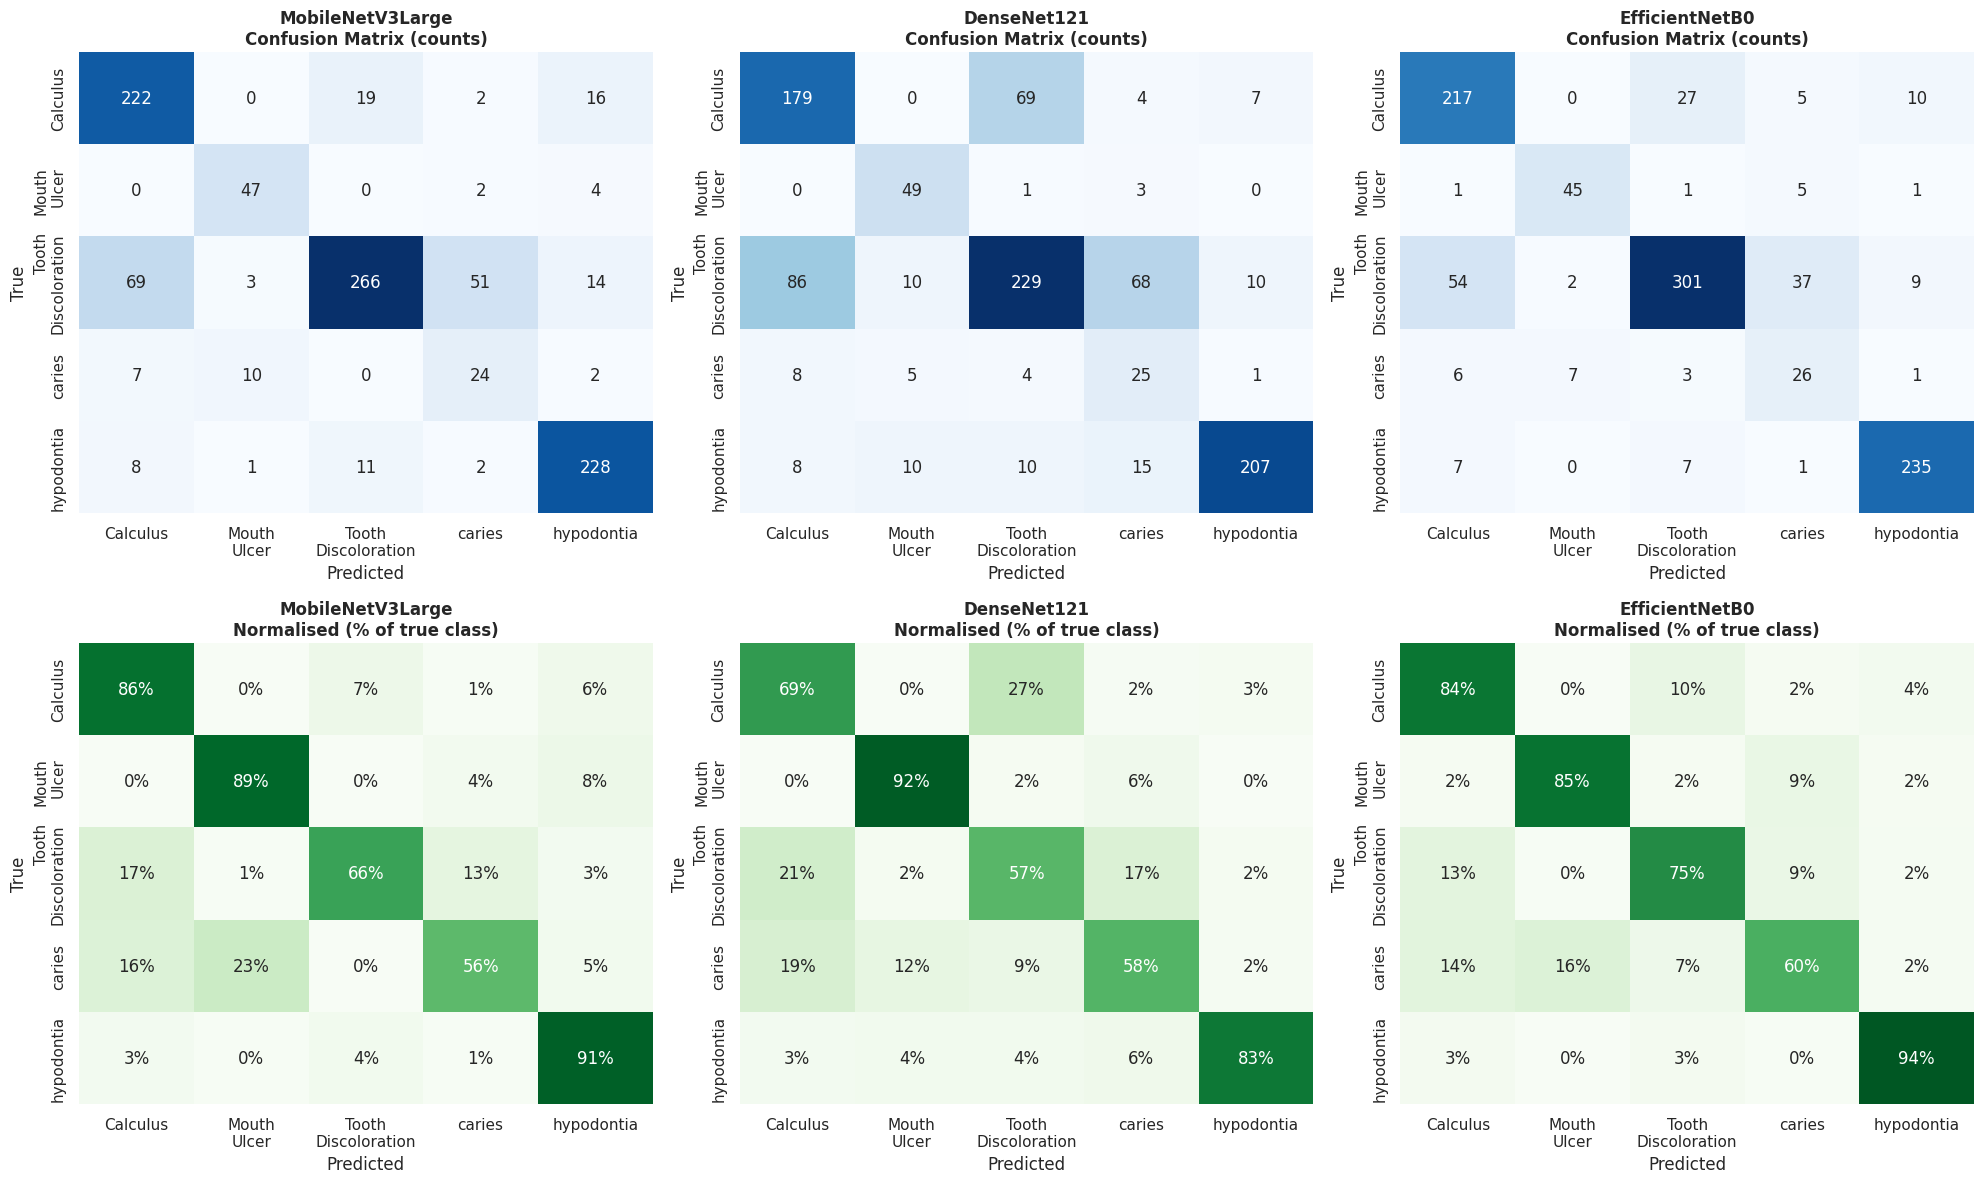

In [ ]:
# Cell 6: Confusion matrices (counts on top, row-normalised % below)
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

sns.set_theme(style='white', font_scale=1.0)
short = [c.replace(' ', '\n') for c in class_names]

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
for j, (name, p) in enumerate(preds.items()):
    cm = confusion_matrix(p['y_true'], p['y_pred'])
    cm_pct = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=short, yticklabels=short, ax=axes[0, j])
    axes[0, j].set_title(f'{name}\nConfusion Matrix (counts)', fontweight='bold')
    sns.heatmap(cm_pct, annot=True, fmt='.0%', cmap='Greens', vmin=0, vmax=1, cbar=False,
                xticklabels=short, yticklabels=short, ax=axes[1, j])
    axes[1, j].set_title(f'{name}\nNormalised (% of true class)', fontweight='bold')
    for ax in axes[:, j]:
        ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.tight_layout()
plt.savefig('/content/confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

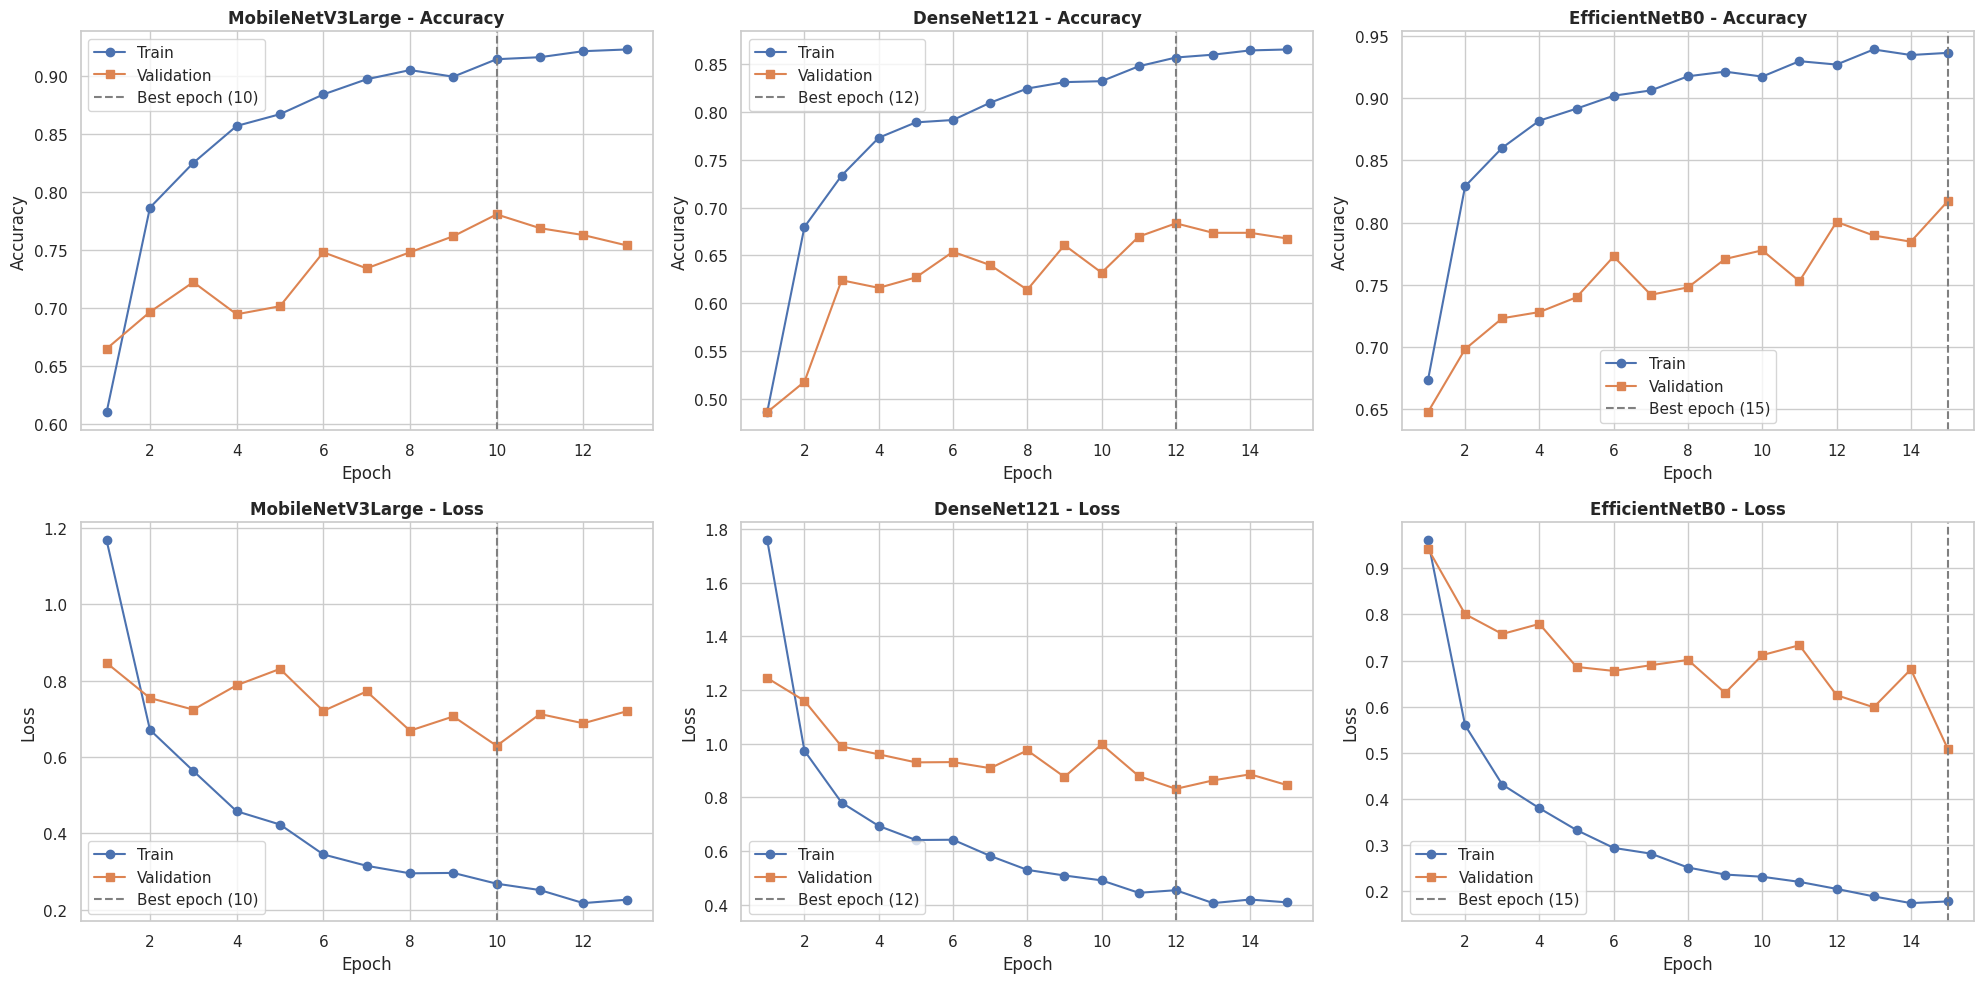

In [ ]:
# Cell 7: Training curves (train vs validation, best epoch marked)
sns.set_theme(style='whitegrid', font_scale=1.0)
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for j, (name, h) in enumerate(histories.items()):
    hist = h.history
    best = int(np.argmin(hist['val_loss']))
    ep = range(1, len(hist['accuracy']) + 1)

    axes[0, j].plot(ep, hist['accuracy'], 'o-', label='Train')
    axes[0, j].plot(ep, hist['val_accuracy'], 's-', label='Validation')
    axes[0, j].axvline(best + 1, color='gray', linestyle='--', label=f'Best epoch ({best + 1})')
    axes[0, j].set_title(f'{name} - Accuracy', fontweight='bold')
    axes[0, j].set_xlabel('Epoch'); axes[0, j].set_ylabel('Accuracy'); axes[0, j].legend()

    axes[1, j].plot(ep, hist['loss'], 'o-', label='Train')
    axes[1, j].plot(ep, hist['val_loss'], 's-', label='Validation')
    axes[1, j].axvline(best + 1, color='gray', linestyle='--', label=f'Best epoch ({best + 1})')
    axes[1, j].set_title(f'{name} - Loss', fontweight='bold')
    axes[1, j].set_xlabel('Epoch'); axes[1, j].set_ylabel('Loss'); axes[1, j].legend()
plt.tight_layout()
plt.savefig('/content/training_curves.png', dpi=300, bbox_inches='tight')
plt.show()

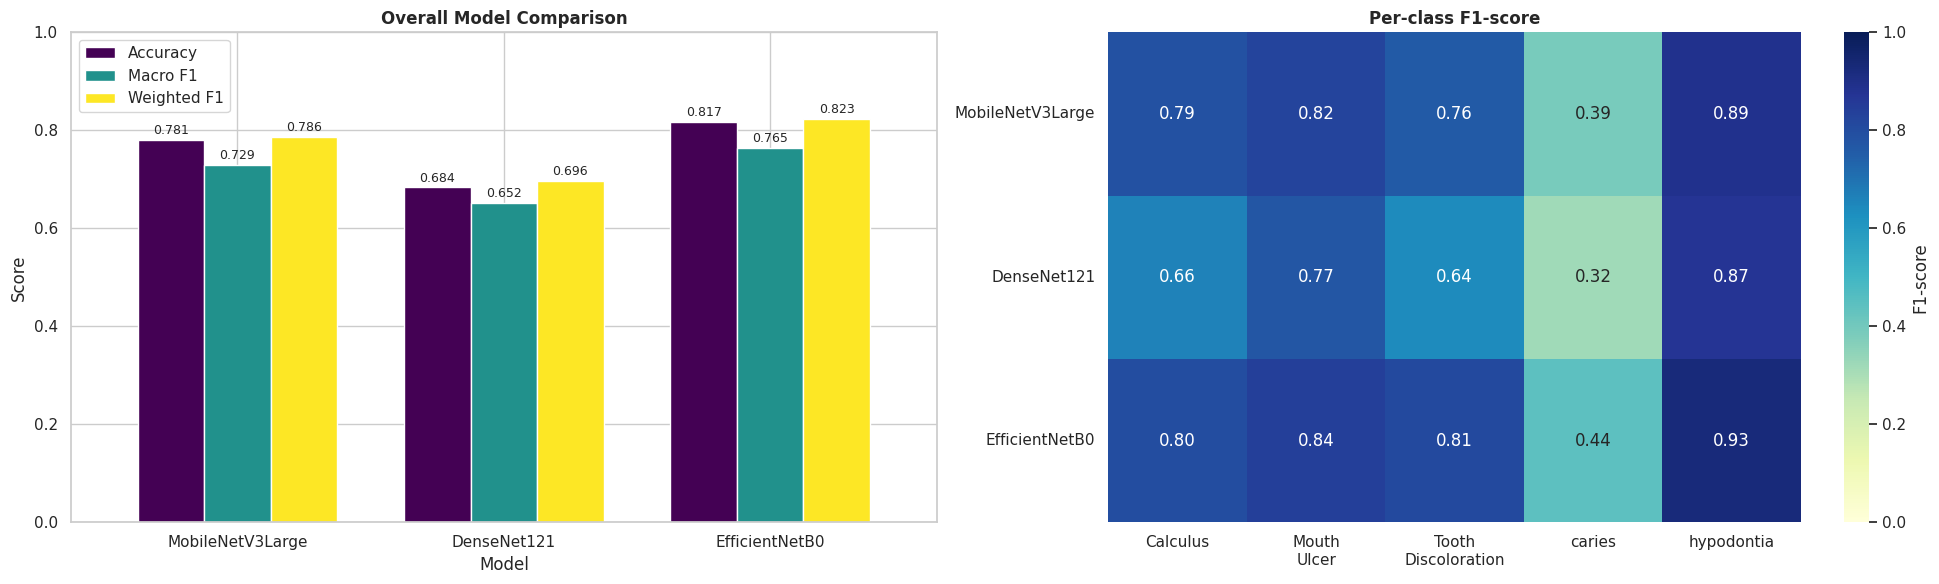

In [ ]:
# Cell 8: Overall metrics bar chart + per-class F1 heatmap
from sklearn.metrics import classification_report

rows, f1_matrix = [], {}
for name, p in preds.items():
    rep = classification_report(p['y_true'], p['y_pred'], target_names=class_names, output_dict=True)
    rows.append({'Model': name, 'Accuracy': rep['accuracy'],
                 'Macro F1': rep['macro avg']['f1-score'],
                 'Weighted F1': rep['weighted avg']['f1-score']})
    f1_matrix[name] = [rep[c]['f1-score'] for c in class_names]

df_overall = pd.DataFrame(rows).set_index('Model')
df_f1 = pd.DataFrame(f1_matrix, index=class_names).T

fig, axes = plt.subplots(1, 2, figsize=(20, 6))
df_overall.plot(kind='bar', ax=axes[0], rot=0, width=0.75, colormap='viridis')
for c in axes[0].containers:
    axes[0].bar_label(c, fmt='%.3f', fontsize=9, padding=2)
axes[0].set_ylim(0, 1); axes[0].set_ylabel('Score')
axes[0].set_title('Overall Model Comparison', fontweight='bold')

sns.heatmap(df_f1, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1, ax=axes[1],
            cbar_kws={'label': 'F1-score'})
axes[1].set_title('Per-class F1-score', fontweight='bold')
axes[1].set_xticklabels([c.replace(' ', '\n') for c in class_names], rotation=0)
axes[1].tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.savefig('/content/metrics_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

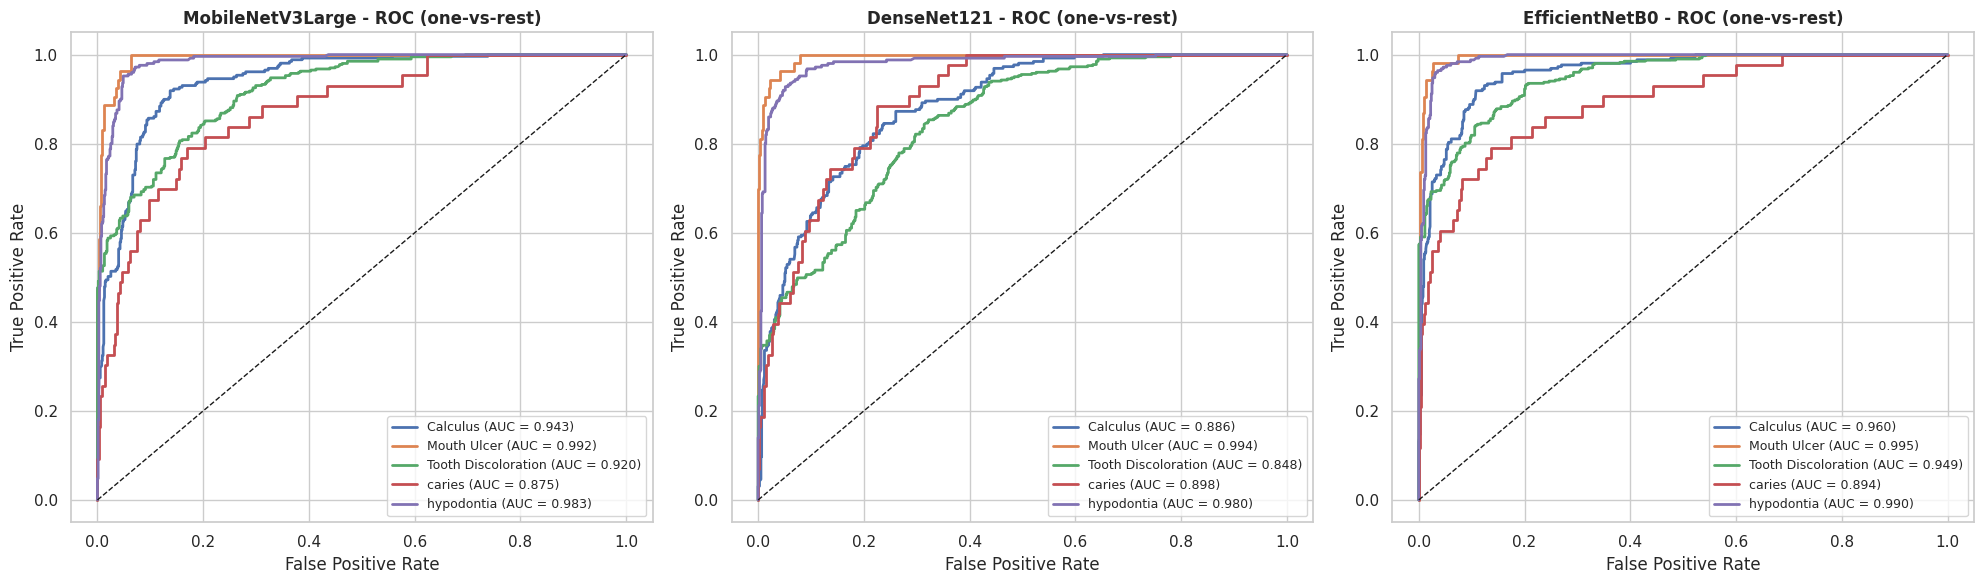

In [ ]:
# Cell 9: ROC curves (one-vs-rest) with AUC per class
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (name, p) in zip(axes, preds.items()):
    y_bin = label_binarize(p['y_true'], classes=range(len(class_names)))
    for i, cname in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_bin[:, i], p['probs'][:, i])
        ax.plot(fpr, tpr, lw=2, label=f'{cname} (AUC = {auc(fpr, tpr):.3f})')
    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.set_title(f'{name} - ROC (one-vs-rest)', fontweight='bold')
    ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
    ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig('/content/roc_curves.png', dpi=300, bbox_inches='tight')
plt.show()

                  Accuracy  Macro F1  Weighted F1  Macro AUC  Params (M)
Model                                                                   
MobileNetV3Large    0.7808    0.7291       0.7861     0.9429      3.1200
DenseNet121         0.6835    0.6525       0.6963     0.9213      7.1693
EfficientNetB0      0.8175    0.7647       0.8229     0.9577      4.2142


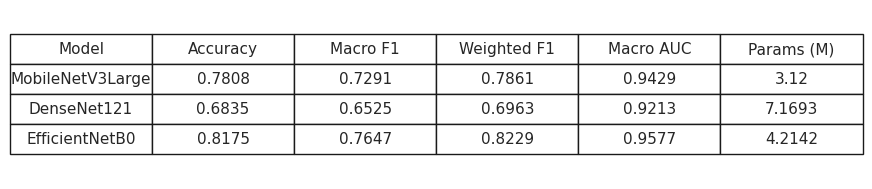

  adding: confusion_matrices.png (deflated 17%)
  adding: metrics_comparison.png (deflated 22%)
  adding: roc_curves.png (deflated 16%)
  adding: summary_table.png (deflated 16%)
  adding: training_curves.png (deflated 14%)
  adding: model_comparison.csv (deflated 23%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Cell 10: Summary table (CSV + image) and download everything
from sklearn.metrics import roc_auc_score

summary = df_overall.copy()
summary['Macro AUC'] = [roc_auc_score(p['y_true'], p['probs'], multi_class='ovr', average='macro')
                        for p in preds.values()]
summary['Params (M)'] = [p['params'] / 1e6 for p in preds.values()]
summary = summary.round(4)
summary.to_csv('/content/model_comparison.csv')
print(summary.to_string())

fig, ax = plt.subplots(figsize=(11, 2.2))
ax.axis('off')
tbl = ax.table(cellText=summary.reset_index().values,
               colLabels=['Model'] + list(summary.columns),
               loc='center', cellLoc='center')
tbl.auto_set_font_size(False); tbl.set_fontsize(11); tbl.scale(1, 1.8)
plt.savefig('/content/summary_table.png', dpi=300, bbox_inches='tight')
plt.show()

# Download all figures in one zip
!zip -j /content/report_figures.zip /content/*.png /content/model_comparison.csv
from google.colab import files
files.download('/content/report_figures.zip')